In [1]:
import torch
import torch.nn as nn
import os
import numpy as np
from torch.utils.data import DataLoader, TensorDataset, Dataset
import torch.nn.functional as F
from torch.optim import Adam
from torch.optim import AdamW
import matplotlib.pyplot as plt
from itertools import product
import math
import matplotlib.pyplot as plt

In [2]:
torch.manual_seed(0)
np.random.seed(0)

In [3]:
### Example Data

n_train = 64 # number of training samples

# Load the data
# Training data: train_sol.npy Shape: (128,5,64)
# Testing datasets: test_sol.npy Shape: (128,5,64)
#                   test_sol_res_{s}.npy Shape: (128,2,s), s in {32, 64, 96, 128}
train_data_ = torch.from_numpy(np.load("train_sol.npy")).type(torch.float32)
test_data = torch.from_numpy(np.load("test_sol.npy")).type(torch.float32)

print(np.shape(train_data_)) #includes all time 5 snapshots and all 128 trajectories
print(np.shape(test_data))

train_data = train_data_[:n_train, :, :] #use 64 trajectories for training
validation_data = train_data_[n_train:, :, :] #the remaining 64 trajectories for validation

batch_size = 8

#print(np.shape(validation_data))

input_function_train = train_data[:, 0, :]
output_function_train = train_data[:, -1, :]
input_function_val = validation_data[:, 0, :]
output_function_val = validation_data[:, -1, :]
input_function_test = test_data[:, 0, :]
output_function_test = test_data[:, -1, :]

#print(np.shape(input_function_train))
#print(np.shape(input_function_val))

grid = np.linspace(0, 1, train_data.shape[2])
grid = torch.tensor(grid, dtype=torch.float32)  # Convert to PyTorch tensor
grid = grid.unsqueeze(0).expand(input_function_train.shape[0], -1) # Expand grid to have shape (1, 64) and then broadcast to (64, 64)
#print(np.shape(grid))

input_function_train = torch.stack((input_function_train, grid), dim=2)
input_function_val = torch.stack((input_function_val, grid), dim=2)

grid_test = np.linspace(0, 1, test_data.shape[2])
grid_test = torch.tensor(grid_test, dtype=torch.float32)  # Convert to PyTorch tensor
grid_test = grid_test.unsqueeze(0).expand(input_function_test.shape[0], -1) # Expand grid to have shape (1, 64) and then broadcast to (128, 64)
#print(np.shape(grid_test))

input_function_test = torch.stack((input_function_test, grid_test), dim=2)

print(np.shape(input_function_train))

training_set = DataLoader(TensorDataset(input_function_train, output_function_train), batch_size=batch_size, shuffle=True) #only use t=0 and t=1 for training
validation_set = DataLoader(TensorDataset(input_function_val, output_function_val), batch_size=batch_size, shuffle=False)

torch.Size([128, 5, 64])
torch.Size([128, 5, 64])
torch.Size([64, 64, 2])


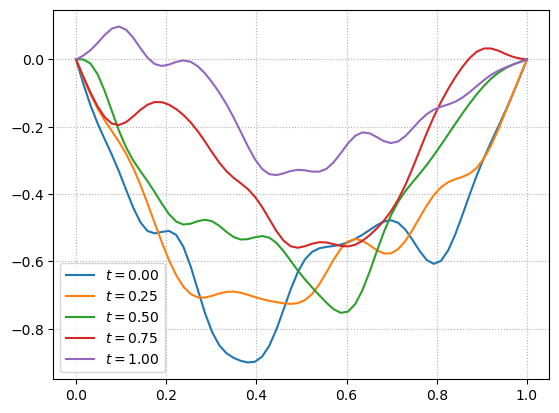

In [4]:
### Example Plotting
sample_id = 42

plt.plot(np.linspace(0, 1, train_data.shape[2]), train_data[sample_id, 0, :], label = "$t = 0.00$")
plt.plot(np.linspace(0, 1, train_data.shape[2]), train_data[sample_id, 1, :], label = "$t = 0.25$")
plt.plot(np.linspace(0, 1, train_data.shape[2]), train_data[sample_id, 2, :], label = "$t = 0.50$")
plt.plot(np.linspace(0, 1, train_data.shape[2]), train_data[sample_id, 3, :], label = "$t = 0.75$")
plt.plot(np.linspace(0, 1, train_data.shape[2]), train_data[sample_id, 4, :], label = "$t = 1.00$")
plt.grid(True, which="both", ls=":")
plt.legend()

In [5]:
class LatentMLP(nn.Module):
    def __init__(self, cin, cout, k, hidden=4):
        super().__init__()
        self.ch_mlp = nn.Sequential(
            nn.Linear(cin, hidden*cin), nn.GELU(),
            nn.Linear(hidden*cin, cout)
        )
        r = max(4, k // 8)
        self.mode_A = nn.Parameter(torch.randn(k, r) / (k**0.5))
        self.mode_B = nn.Parameter(torch.randn(r, k) / (r**0.5))
        self.norm = nn.LayerNorm(cout)

    def forward(self, coeffs):            # (B, Cin, k)
        x = coeffs.transpose(1, 2)        # (B, k, Cin)
        x = self.ch_mlp(x)                # (B, k, Cout)
        M = self.mode_A @ self.mode_B     # (k, k)
        x = torch.einsum('km,bmc->bkc', M, x)
        return self.norm(x).transpose(1, 2)  # (B, Cout, k)

# ---------- Dense (PCA/AS) encoder ----------
class DenseEncoder1D(nn.Module):
    def __init__(self, N, k, basis=None, learnable=True, mean=None):
        super().__init__()
        self.N, self.k = N, k
        if basis is None:
            B0 = torch.randn(N, k)
            B0, _ = torch.linalg.qr(B0, mode='reduced')
        else:
            B0 = basis[:, :k].contiguous()

        if learnable:
            self.B_param = nn.Parameter(B0)   # learnable basis
            self.register_buffer("B_buf", None)
        else:
            self.register_buffer("B_buf", B0) # fixed basis
            self.B_param = None

        self.register_buffer("mean", mean if mean is not None else None)
        self._oja_buf = None
        self._oja_eta = 1e-3

    def _B(self):
        return self.B_param if self.B_param is not None else self.B_buf

    def encode(self, x):  # x: (B,C,N) -> (B,C,k)
        xc = x - self.mean.view(1,1,-1) if self.mean is not None else x
        return torch.einsum("bcn,nk->bck", xc, self._B())

    def decode(self, z):  # z: (B,C,k) -> (B,C,N)
        out = torch.einsum("nk,bck->bcn", self._B(), z)
        if self.mean is not None:
            out = out + self.mean.view(1,1,-1)
        return out

    @torch.no_grad()
    def oja_update_step(self):
        if self.B_param is None or self._oja_buf is None:
            self._oja_buf = None
            return
        U = self.B_param.data             # (N,k)
        s = self._oja_buf                 # (N,)
        proj  = U.T @ s                   # (k,)
        resid = s - U @ proj              # (N,)
        U += self._oja_eta * (resid[:, None] @ proj[None, :])
        self.B_param.data.copy_(U)
        self._oja_buf = None

# ---------- Learned butterfly transform ----------
class Butterfly1D(nn.Module):
    """
    Simple learned butterfly-like transform (power-of-two length via padding).
    Applies log2(P) stages of 2x2 mixing. Same weights across channels for simplicity.
    """
    def __init__(self, N):
        super().__init__()
        P = 1 << (N - 1).bit_length()
        self.N, self.P = N, P
        self.stages = int(math.log2(P))
        self.mix = nn.ParameterList()
        for s in range(self.stages):
            # one 2x2 mixing per stride-2 pair; share across positions
            W = torch.eye(2)
            W = W + 0.01*torch.randn_like(W)
            self.mix.append(nn.Parameter(W))  # (2,2)

    def forward(self, x):  # x: (B,C,N) -> (B,C,P)
        B,C,N = x.shape
        if self.P > N:
            pad = torch.zeros(B,C,self.P-N, device=x.device, dtype=x.dtype)
            x = torch.cat([x, pad], dim=-1)
        y = x
        P = self.P
        for s in range(self.stages):
            # reshape into (B,C, P/2, 2), apply 2x2
            y = y.view(B, C, -1, 2)
            W = self.mix[s]  # (2,2)
            y = torch.einsum('ij,bcqj->bcqi', W, y)  # (B,C,P/2,2)
            y = y.reshape(B, C, P)
            # butterfly shuffle: swap within each 2-block to emulate stage permutations
            # (lightweight; real butterfly needs structured permutations)
            y = y.view(B, C, P//2, 2).flip(-1).reshape(B, C, P)
        return y

    def inverse(self, y):  # approximate inverse using per-stage inverse
        B,C,P = y.shape
        x = y
        for s in reversed(range(self.stages)):
            x = x.view(B, C, -1, 2)
            W = self.mix[s]
            Winv = torch.inverse(W)
            x = torch.einsum('ij,bcqj->bcqi', Winv, x)
            x = x.reshape(B, C, P)
            x = x.view(B, C, P//2, 2).flip(-1).reshape(B, C, P)
        x = x[..., :self.N]
        return x

class ButterflyEncoder1D(nn.Module):
    """
    Encode by applying a learned butterfly transform, then selecting k indices.
    Decode by scattering back and applying inverse transform.
    """
    def __init__(self, N, k, select_idx=None):
        super().__init__()
        self.N, self.k = N, k
        self.bt = Butterfly1D(N)
        if select_idx is None:
            # default: first k positions in transform domain
            select_idx = torch.arange(k, dtype=torch.long)
        self.register_buffer("idx", select_idx.view(1,1,-1))  # (1,1,k)
        self._oja_buf = None
        self._oja_eta = 1e-3

    def encode(self, x):                 # x: (B,C,N) -> (B,C,k)
        y = self.bt(x)                   # (B,C,P)
        z = torch.gather(y, dim=-1, index=self.idx.expand(y.size(0), y.size(1), -1))
        return z

    def decode(self, z):                 # (B,C,k) -> (B,C,N)
        B,C,k = z.shape
        P = self.bt.P
        y = torch.zeros(B,C,P, device=z.device, dtype=z.dtype)
        y.scatter_(dim=-1, index=self.idx.expand(B,C,-1), src=z)
        x = self.bt.inverse(y)           # (B,C,N)
        return x

    @torch.no_grad()
    def oja_update_step(self):
        # Here we could adapt 'idx' using a simple leverage-score proxy from _oja_buf,
        # but we keep butterfly weights as the adaptable part.
        self._oja_buf = None
        return

# ---------- Hierarchical (block low-rank) encoder ----------
class HierarchicalEncoder1D(nn.Module):
    """
    Patchwise low-rank encoder: split N into num_blocks, each with rank r.
    k = num_blocks * r. Two-level 'hierarchical' feel with local bases.
    """
    def __init__(self, N, num_blocks: int, r: int):
        super().__init__()
        assert N % num_blocks == 0, "Choose num_blocks that divides N"
        self.N, self.num_blocks, self.r = N, num_blocks, r
        self.block = N // num_blocks
        # local bases: (num_blocks, block, r)
        B = torch.randn(num_blocks, self.block, r)
        for b in range(num_blocks):
            Q, _ = torch.linalg.qr(B[b], mode='reduced')
            B[b] = Q
        self.Bloc = nn.Parameter(B)
        self._oja_buf = None
        self._oja_eta = 1e-3

    def encode(self, x):  # (B,C,N) -> (B,C, num_blocks*r)
        B,C,N = x.shape
        xb = x.view(B, C, self.num_blocks, self.block)  # (B,C,nb,block)
        z = torch.einsum("bcnq,nqr->bcnr", xb, self.Bloc)  # (B,C,nb,r)
        return z.reshape(B, C, self.num_blocks*self.r)

    def decode(self, z):  # (B,C, nb*r) -> (B,C,N)
        B,C,_ = z.shape
        zb = z.view(B, C, self.num_blocks, self.r)      # (B,C,nb,r)
        xhat = torch.einsum("nqr,bcnr->bcnq", self.Bloc, zb)  # (B,C,nb,block)
        return xhat.reshape(B, C, self.N)

    @torch.no_grad()
    def oja_update_step(self):
        if self._oja_buf is None: return
        # simple: update each local basis against local gradient slice
        g = self._oja_buf  # (N,)
        g_blocks = g.view(self.num_blocks, self.block)
        for b in range(self.num_blocks):
            U = self.Bloc.data[b]        # (block,r)
            s = g_blocks[b]              # (block,)
            proj = U.T @ s               # (r,)
            resid = s - U @ proj
            U += self._oja_eta * (resid[:, None] @ proj[None, :])
            # orthonormalize (cheap, block-sized)
            Q, _ = torch.linalg.qr(U, mode='reduced')
            self.Bloc.data[b].copy_(Q)
        self._oja_buf = None

# ---------- The unified RB layer ----------
class RBLayer1d(nn.Module):
    def __init__(self, in_ch, out_ch, N, k, mode="dense",
                 basis=None, learn_basis=True, mean=None,
                 hidden=4, hier_num_blocks=8, hier_r=4, butterfly_idx=None):
        super().__init__()
        self.in_ch, self.out_ch, self.N, self.k, self.mode = in_ch, out_ch, N, k, mode
        if mode == "dense":
            self.enc = DenseEncoder1D(N, k, basis=basis, learnable=learn_basis, mean=mean)
        elif mode == "butterfly":
            self.enc = ButterflyEncoder1D(N, k, select_idx=butterfly_idx)
        elif mode == "hierarchical":
            self.enc = HierarchicalEncoder1D(N, num_blocks=hier_num_blocks, r=hier_r)
            assert hier_num_blocks*hier_r == k, "k must equal num_blocks * r"
        else:
            raise ValueError("mode must be one of: dense, butterfly, hierarchical")

        self.latent = LatentMLP(in_ch, out_ch, k, hidden=hidden)
        self.bias = nn.Parameter(torch.zeros(out_ch))

    def forward(self, x):   # x: (B, in_ch, N)
        coeffs = self.enc.encode(x)               # (B, in_ch, k)
        out_coeffs = self.latent(coeffs)          # (B, out_ch, k)
        out = self.enc.decode(out_coeffs)         # (B, out_ch, N)
        return out + self.bias.view(1, -1, 1)

    # called by apply_oja_update
    def oja_update_step(self):
        if hasattr(self.enc, "_oja_buf"):
            self.enc.oja_update_step()

In [6]:
class MRBNO1D(nn.Module):
    def __init__(self, N, modes, width,
                 mode1="dense", mode2="dense", mode3="dense",
                 basis=None, learn_basis=True, mean=None,
                 hidden=4, hier_conf=(8,4), butterfly_idx=None):
        super().__init__()
        self.width = width
        self.linear_p = nn.Linear(2, width)
        self.bn_in = nn.BatchNorm1d(width)
        self.dropout = nn.Dropout(0.1)

        # RB layers
        nb, r = hier_conf  # for hierarchical mode (num_blocks, rank)
        self.rb1 = RBLayer1d(width, width, N, modes, mode=mode1,
                             basis=basis, learn_basis=learn_basis, mean=mean,
                             hidden=hidden, hier_num_blocks=nb, hier_r=r, butterfly_idx=butterfly_idx)
        self.rb2 = RBLayer1d(width, width, N, modes, mode=mode2,
                             basis=basis, learn_basis=learn_basis, mean=mean,
                             hidden=hidden, hier_num_blocks=nb, hier_r=r, butterfly_idx=butterfly_idx)
        self.rb3 = RBLayer1d(width, width, N, modes, mode=mode3,
                             basis=basis, learn_basis=learn_basis, mean=mean,
                             hidden=hidden, hier_num_blocks=nb, hier_r=r, butterfly_idx=butterfly_idx)

        # local 1x1 convs + norms
        self.lin0 = nn.Conv1d(width, width, 1)
        self.lin1 = nn.Conv1d(width, width, 1)
        self.lin2 = nn.Conv1d(width, width, 1)
        self.bn1 = nn.BatchNorm1d(width)
        self.bn2 = nn.BatchNorm1d(width)
        self.bn3 = nn.BatchNorm1d(width)

        self.linear_q = nn.Linear(width, 32)
        self.out = nn.Linear(32, 1)
        self.act = nn.Tanh()

    def forward(self, x):       # x: (B, N, 2)
        x = self.linear_p(x)    # (B,N,width)
        x = x.permute(0,2,1)    # (B,width,N)
        x = self.bn_in(x)

        x = self.act(self.rb1(x) + self.lin0(x)); x = self.bn1(x); x = self.dropout(x)
        x = self.act(self.rb2(x) + self.lin1(x)); x = self.bn2(x); x = self.dropout(x)
        x = self.act(self.rb3(x) + self.lin2(x)); x = self.bn3(x); x = self.dropout(x)

        x = x.permute(0,2,1)    # (B,N,width)
        x = self.act(self.linear_q(x))
        return self.out(x)      # (B,N,1)

In [7]:
def attach_oja_hook_rb(layer: RBLayer1d, eta=1e-3):
    layer.enc._oja_eta = eta
    def _save_grad(module, grad_input, grad_output):
        if grad_input and grad_input[0] is not None:
            g = grad_input[0].detach().mean(dim=(0,1))  # (N,)
            layer.enc._oja_buf = g
    layer._hook = layer.register_full_backward_hook(_save_grad)  # uses nn.Module API. :contentReference[oaicite:1]{index=1}

def orthonormality_penalty_dense(model: nn.Module, lam=1e-3):
    reg = 0.0
    for m in model.modules():
        if isinstance(m, RBLayer1d) and isinstance(m.enc, DenseEncoder1D):
            if isinstance(m.enc.B_param, nn.Parameter):
                B = m.enc.B_param
                BtB = B.T @ B
                I = torch.eye(BtB.size(0), device=B.device, dtype=B.dtype)
                reg = reg + ((BtB - I) ** 2).sum()
    return lam * reg

@torch.no_grad()
def reorthonormalize_dense_bases(model: nn.Module):
    for m in model.modules():
        if isinstance(m, RBLayer1d) and isinstance(m.enc, DenseEncoder1D):
            if isinstance(m.enc.B_param, nn.Parameter):
                Q, _ = torch.linalg.qr(m.enc.B_param.data, mode='reduced')  # QR is the standard way to re-orthonormalize. :contentReference[oaicite:2]{index=2}
                m.enc.B_param.data.copy_(Q)

@torch.no_grad()
def apply_oja_update(model: nn.Module):
    for m in model.modules():
        if isinstance(m, RBLayer1d):
            m.oja_update_step()

### Initial Basis Computation Helpers
def compute_pca_basis_from_snapshots(snapshots: torch.Tensor, modes: int, center: bool = True):
    """
    snapshots: (S, N) or (S, C, N). Returns basis (N, modes) with orthonormal columns.
    """
    if snapshots.dim() == 3:
        S, C, N = snapshots.shape
        X = snapshots.reshape(S * C, N)
    elif snapshots.dim() == 2:
        X = snapshots
    else:
        raise ValueError("snapshots must be shape (S, N) or (S, C, N)")

    X = X.to(torch.get_default_dtype())
    if center:
        mean = X.mean(dim=0, keepdim=True)
        Xc = X - mean
    else:
        Xc = X

    # thin SVD
    U, Svals, Vh = torch.linalg.svd(Xc, full_matrices=False)
    V = Vh.conj().T  # (N, N)
    basis = V[:, :modes].contiguous()  # (N, modes)
    return basis

def build_snapshots_from_dataset(training_set, which='output'):
    """
    Build snapshots from training_set by concatenating either outputs or inputs.
    `training_set` is expected to yield (input_batch, output_batch).
    which: 'output' or 'input' (use output snapshots by default)
    Returns snapshots tensor (S, N) or (S, C, N) depending on data.
    """
    parts = []
    for (inp, out) in training_set:
        if which == 'output':
            y = out
            # Expect out shape (batch, N) or (batch, N, 1) or (batch, N, channels)
            if y.dim() == 3 and y.size(-1) == 1:
                # maybe (batch, N, 1) -> (batch, N)
                y = y.squeeze(-1)
            # If (batch, N) -> (batch, N)
            if y.dim() == 2:
                parts.append(y)               # (b, N)
            elif y.dim() == 3:               # (b, N, C) -> (b, C, N)
                parts.append(y.permute(0, 2, 1))  # (b, C, N)
            else:
                raise ValueError("unexpected output_batch shape")
        else:
            x = inp
            # handle input shape (batch, N, 2) -> (batch, N) or (batch, N, channels)
            if x.dim() == 3:
                parts.append(x.permute(0, 2, 1))  # (b, C, N)
            elif x.dim() == 2:
                parts.append(x)
            else:
                raise ValueError("unexpected input_batch shape")
    if len(parts) == 0:
        raise RuntimeError("training_set empty")
    # try to stack and return a 2D or 3D snapshot array
    # If parts[0] is (b,N) -> stacked -> (total_samples, N)
    # If parts[0] is (b,C,N) -> concat along 0 -> (total_samples, C, N)
    p0 = parts[0]
    if p0.dim() == 2:
        return torch.cat(parts, dim=0)           # (S, N)
    else:
        return torch.cat(parts, dim=0)           # (S, C, N)



def attach_oja_hook(layer, eta=1e-3):
    layer._oja_eta = eta
    layer._oja_buf = None
    def _save_grad(module, grad_input, grad_output):
        if grad_input and grad_input[0] is not None:
            g = grad_input[0].detach().mean(dim=(0,1))  # (N,)
            layer._oja_buf = g
    layer._hook = layer.register_full_backward_hook(_save_grad)

@torch.no_grad()
def apply_oja_update(model):
    for m in model.modules():
        if hasattr(m, "oja_update_step"):
            m.oja_update_step()  # delegates to the encoder mode (dense/butterfly/hierarchical)

In [8]:
# 1) Compute PCA basis + mean (as you already do)

learning_rate = 0.001

epochs = 250 # 10

step_size = 50

gamma = 0.5

modes = 16 # 12

width = 64 # 32

N = 64


basis = compute_pca_basis_from_snapshots(train_data, modes)   # (N, modes)
mean  = train_data.reshape(-1, n_train).mean(dim=0)

# 2) Build model with mixed modes
model = MRBNO1D(N=N, modes=modes, width=width,
                mode1="dense", mode2="butterfly", mode3="hierarchical",
                basis=basis, learn_basis=True, mean=mean,
                hidden=4, hier_conf=(8, modes//8))

# 3) Attach Oja hooks to later layers
attach_oja_hook(model.rb2, eta=1e-3)
attach_oja_hook(model.rb3, eta=1e-3)

In [9]:
def train_mrbno(
    modes, width, epochs, learning_rate, step_size, gamma,
    training_set, validation_set, snapshots=None,
    # model/config:
    mode1="dense", mode2="dense", mode3="dense",
    hier_conf=(8, 4), butterfly_idx=None,
    learn_basis=True, share_dense_basis=True,
    basis_reg_lambda=1e-3, reorth_every=50,
    oja_eta=1e-3, oja_on=("rb2","rb3"),
    device=None, verbose_every=50
):
    """
    Train MRBNO1D with dense|butterfly|hierarchical encoders and Oja adaptation.

    training_set/validation_set: iterables yielding (input_batch, output_batch)
                                 input_batch: (B, N, 2), output_batch: (B, N) or (B, N, 1)
    """
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")

    # ---- Build snapshots if not provided ----
    if snapshots is None:
        print("Building snapshots from training_set outputs...")
        snapshots = build_snapshots_from_dataset(training_set, which='output')  # (S,N) or (S,C,N)

    # ---- Derive N, compute PCA basis + mean (for dense mode & centering) ----
    if snapshots.dim() == 3:
        _, C, N = snapshots.shape
        mean = snapshots.reshape(-1, N).mean(dim=0)
    else:
        _, N = snapshots.shape
        mean = snapshots.mean(dim=0)

    basis = compute_pca_basis_from_snapshots(snapshots, modes)  # (N, modes)

    # ---- Instantiate model ----
    model = MRBNO1D(
        N=N, modes=modes, width=width,
        mode1=mode1, mode2=mode2, mode3=mode3,
        basis=basis if mode1=="dense" else None,   # rb1 basis
        learn_basis=learn_basis, mean=mean,
        hidden=4, hier_conf=hier_conf, butterfly_idx=butterfly_idx
    ).to(device)

    # If later layers are dense and user wants to share basis, tie their Parameters
    if share_dense_basis:
        refB = None
        # grab rb1 dense basis if present
        if isinstance(model.rb1.enc, DenseEncoder1D) and isinstance(model.rb1.enc.B_param, nn.Parameter):
            refB = model.rb1.enc.B_param

        for rb in [model.rb2, model.rb3]:
            if isinstance(rb.enc, DenseEncoder1D) and isinstance(rb.enc.B_param, nn.Parameter) and refB is not None:
                rb.enc.B_param = refB  # share the same Parameter object

    # ---- Oja hooks on selected layers ----
    if "rb1" in oja_on: attach_oja_hook_rb(model.rb1, eta=oja_eta)
    if "rb2" in oja_on: attach_oja_hook_rb(model.rb2, eta=oja_eta)
    if "rb3" in oja_on: attach_oja_hook_rb(model.rb3, eta=oja_eta)

    # ---- Optimizer, scheduler, loss ----
    optimizer = Adam(model.parameters(), lr=learning_rate, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=step_size, gamma=gamma)
    criterion = torch.nn.MSELoss()

    # ---- Training loop ----
    last_validation_rel_l2 = None
    step = 0
    for epoch in range(epochs):
        model.train()
        train_mse = 0.0
        n_steps = 0

        for (inp, out) in training_set:
            # shapes -> device
            inp = inp.to(device)                       # (B, N, 2)
            if out.dim() == 3 and out.size(-1) == 1:
                out = out.squeeze(-1)
            out = out.to(device)                       # (B, N)

            optimizer.zero_grad()
            pred = model(inp).squeeze(2)               # (B, N)

            loss_f = criterion(pred, out)

            # orthonormality penalty only affects dense learnable encoders
            loss_reg = orthonormality_penalty_dense(model, lam=basis_reg_lambda)

            loss = loss_f + loss_reg
            loss.backward()

            # Oja (no-grad) then optimize
            apply_oja_update(model)
            optimizer.step()

            # keep dense bases on Stiefel (occasionally)
            if reorth_every and (step % reorth_every == 0):
                reorthonormalize_dense_bases(model)

            train_mse += loss_f.item()
            n_steps += 1
            step += 1

        if n_steps > 0:
            train_mse /= n_steps

        scheduler.step()

        # ---- Validation ----
        model.eval()
        test_relative_l2 = 0.0
        n_val = 0
        with torch.no_grad():
            for (inp, out) in validation_set:
                inp = inp.to(device)
                if out.dim() == 3 and out.size(-1) == 1:
                    out = out.squeeze(-1)
                out = out.to(device)

                pred = model(inp).squeeze(2)
                rel_l2 = (torch.mean((pred - out) ** 2) / torch.mean(out ** 2)).sqrt() * 100.0
                test_relative_l2 += rel_l2.item()
                n_val += 1
        if n_val > 0:
            test_relative_l2 /= n_val
            last_validation_rel_l2 = test_relative_l2

        if (epoch % verbose_every) == 0:
            print(f"Epoch {epoch:4d} | Train MSE: {train_mse:.6e} | Val Rel-L2 (%): {test_relative_l2:.4f}")

    return model, last_validation_rel_l2


In [10]:
model, val_rel_l2 = train_mrbno(
    modes=32, width=64, epochs=200, learning_rate=2e-3, step_size=50, gamma=0.5,
    training_set=training_set,            # <-- pass DataLoader, not raw tensors
    validation_set=validation_set,        # <--
    mode1="dense", mode2="butterfly", mode3="hierarchical",
    hier_conf=(8, 4),                     # ensure 8*4 == modes
    share_dense_basis=True,
    oja_eta=1e-3, oja_on=("rb2","rb3"),
    basis_reg_lambda=1e-3, reorth_every=50
)

Building snapshots from training_set outputs...
Epoch    0 | Train MSE: 7.963078e-02 | Val Rel-L2 (%): 113.7575
Epoch   50 | Train MSE: 6.449236e-03 | Val Rel-L2 (%): 39.7689
Epoch  100 | Train MSE: 4.494849e-03 | Val Rel-L2 (%): 33.1108
Epoch  150 | Train MSE: 3.223767e-03 | Val Rel-L2 (%): 28.7128


Relative L2 error (sample 42): 20.368%
Average relative L2 error: 31.987%


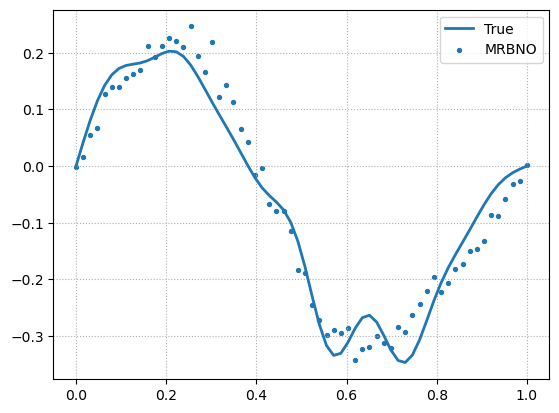

In [11]:
device = next(model.parameters()).device

data_id = 42
input_function_test_n  = input_function_test[data_id, :, :].unsqueeze(0).to(device)  # (1, N, 2)
output_function_test_n = output_function_test[data_id, :].unsqueeze(0).to(device)    # (1, N)

with torch.no_grad():
    pred = model(input_function_test_n).squeeze(2)  # (1, N)

plt.figure()
plt.grid(True, which="both", ls=":")
x_grid = input_function_test_n[0,:,1].detach().cpu()      # the coordinate
plt.plot(x_grid, output_function_test_n[0].detach().cpu(), label="True", lw=2)
plt.scatter(x_grid, pred[0].detach().cpu(), label="MRBNO", s=8)
plt.legend()

# sample relative L2
err_sample = (torch.mean((pred - output_function_test_n) ** 2) /
              torch.mean(output_function_test_n ** 2)).sqrt() * 100.0
print(f"Relative L2 error (sample {data_id}): {err_sample.item():.3f}%")

# average relative L2 over test set
avg_err = 0.0
with torch.no_grad():
    for data_id in range(test_data.shape[0]):
        x = input_function_test[data_id, :, :].unsqueeze(0).to(device)
        y = output_function_test[data_id, :].unsqueeze(0).to(device)
        yhat = model(x).squeeze(2)
        avg_err += (torch.mean((yhat - y) ** 2) / torch.mean(y ** 2)).sqrt()
avg_err = (avg_err / test_data.shape[0]) * 100.0
print(f"Average relative L2 error: {avg_err.item():.3f}%")